In [1]:
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties
import matplotlib.font_manager
import pandas as pd
from pathlib import Path

import matplotlib as mpl

from matplotlib.patches import Patch
from matplotlib.lines import Line2D



fpath = Path(mpl.get_data_path(), "/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf")


from matplotlib.font_manager import FontProperties
from matplotlib import font_manager
plt.rcParams['figure.dpi'] = 300
font_path = "/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf"
font_manager.fontManager.addfont("/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf")
prop = font_manager.FontProperties(fname=font_path)
plt.rcParams['svg.fonttype']='none'

In [2]:
%%bash
mkdir datasets/RNA_seq
cd datasets/RNA_seq 
wget https://ftp.ncbi.nlm.nih.gov/genomes/all/GCF/014/529/535/GCF_014529535.2_BU_Bcop_v2.1/GCF_014529535.2-RS_2026_02_gene_expression_counts.txt.gz
gunzip GCF_014529535.2-RS_2026_02_gene_expression_counts.txt.gz
wget https://ftp.ncbi.nlm.nih.gov/genomes/all/GCF/014/529/535/GCF_014529535.2_BU_Bcop_v2.1/GCF_014529535.2-RS_2026_02_normalized_gene_expression_counts.txt.gz
gunzip GCF_014529535.2-RS_2026_02_normalized_gene_expression_counts.txt.gz
wget https://ftp.ncbi.nlm.nih.gov/genomes/all/GCF/014/529/535/GCF_014529535.2_BU_Bcop_v2.1/GCF_014529535.2-RS_2026_02_rnaseq_runs.txt


mkdir: cannot create directory ‘datasets/RNA_seq’: File exists
--2026-07-07 11:35:06--  https://ftp.ncbi.nlm.nih.gov/genomes/all/GCF/014/529/535/GCF_014529535.2_BU_Bcop_v2.1/GCF_014529535.2-RS_2026_02_gene_expression_counts.txt.gz
Resolving ftp.ncbi.nlm.nih.gov... 130.14.250.12, 130.14.250.13, 2607:f220:41e:250::7, ...
Connecting to ftp.ncbi.nlm.nih.gov|130.14.250.12|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2502419 (2.4M) [application/x-gzip]
Saving to: ‘GCF_014529535.2-RS_2026_02_gene_expression_counts.txt.gz’

     0K .......... .......... .......... .......... ..........  2% 2.22M 1s
    50K .......... .......... .......... .......... ..........  4% 28.7M 1s
   100K .......... .......... .......... .......... ..........  6% 4.15M 1s
   150K .......... .......... .......... .......... ..........  8% 36.7M 0s
   200K .......... .......... .......... .......... .......... 10% 4.24M 0s
   250K .......... .......... .......... .......... .......... 12%  1

In [2]:
dfriso=pd.read_csv("outputs/per_protein_diamond_data.tsv",sep="\t",index_col="accession")

## Pooled expression data from all runs/bioprojects

In [3]:
##load tpm and metadata from refseq
import pandas as pd
metadata=pd.read_csv("datasets/RNA_seq/GCF_014529535.2-RS_2026_02_rnaseq_runs.txt",sep="\t",index_col=0)
tpm=pd.read_csv("datasets/RNA_seq/GCF_014529535.2-RS_2026_02_normalized_gene_expression_counts.txt",sep="\t",index_col=0)
tpm=tpm.loc[:,[x for x in tpm.columns if 'SRR' in x]]



In [4]:
set(metadata['Bioproject Accession'])

{'PRJNA1109384', 'PRJNA1220056', 'PRJNA291918', 'PRJNA928089'}

In [5]:
metadata.loc[:,['Sample Name','Bioproject Accession']].to_csv("outputs/sra_accessions.tsv",sep="\t")

In [6]:
m=tpm.mean(axis=1)
 
hgt_genes=set(dfriso[dfriso.tree_HTG].gene)
dipt_genes=set(dfriso[dfriso['type']=='dipt'].gene)

In [7]:
m.to_csv("outputs/mean_tpms.tsv",sep="\t")

In [8]:

mi=m[m.index.isin(hgt_genes)]
##proportion with expression >100 TPM
count_hgt=mi[mi>100].shape[0]
obs_hgt=mi.shape[0]
count_hgt,count_hgt/obs_hgt

(105, 0.06921555702043507)

In [9]:

mi=m[m.index.isin(hgt_genes)]
##proportion with expression >1 TPM
count_hgt=mi[mi>1].shape[0]
obs_hgt=mi.shape[0]
count_hgt, count_hgt/obs_hgt

(1141, 0.7521423862887278)

In [10]:

mi=m[m.index.isin(hgt_genes)]
##proportion with expression >10 TPM
count_hgt=mi[mi>10].shape[0]
obs_hgt=mi.shape[0]
count_hgt,count_hgt/obs_hgt

(557, 0.3671720500988794)

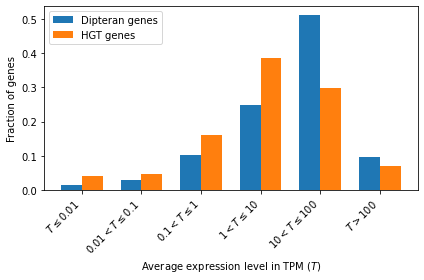

In [12]:
import numpy as np

dipt=list(m[m.index.isin(dipt_genes)])
hgt= list(m[m.index.isin(hgt_genes)])


vmap1 = {
    'T<=0.01': len([x for x in dipt if x <= 0.01]),
    '0.01<T<=0.1': len([x for x in dipt if 0.01 < x <= 0.1]),
    '0.1<T<=1': len([x for x in dipt if 0.1 < x <= 1]),
    '1<T<=10': len([x for x in dipt if 1 < x <= 10]),
    '10<T<=100': len([x for x in dipt if 10 < x <= 100]),
    'T>100': len([x for x in dipt if x > 100])
}
vmap1={x:vmap1[x]/len(dipt) for x in vmap1}

hgt = list(m.loc[list(hgt_genes)])

# Initialize the dictionary to store the counts
vmap2 = {
    'T<=0.01': len([x for x in hgt if x <= 0.01]),
    '0.01<T<=0.1': len([x for x in hgt if 0.01 < x <= 0.1]),
    '0.1<T<=1': len([x for x in hgt if 0.1 < x <= 1]),
    '1<T<=10': len([x for x in hgt if 1 < x <= 10]),
    '10<T<=100': len([x for x in hgt if 10 < x <= 100]),
    'T>100': len([x for x in hgt if x > 100])
}

vmap2={x:vmap2[x]/len(hgt) for x in vmap2}
# Data preparation for plotting
categories = list(vmap1.keys())
counts1 = list(vmap1.values())
counts2 = list(vmap2.values())

# Number of categories
n = len(categories)

# Bar width
bar_width = 0.35

# X locations for the groups
index = np.arange(n)

# Plotting


# Plot bars for the first dataset
plt.bar(index, counts1, bar_width, label='Dipteran genes')

# Plot bars for the second dataset, with an offset
plt.bar(index + bar_width, counts2, bar_width, label='HGT genes')

# Adding labels and title
plt.xlabel('RNA-Seq expression level by ancestry')
plt.ylabel('Fraction of genes')
plt.xlabel(r'Average expression level in TPM ($T$)')
plt.xticks(index + bar_width / 2, [r'$T\leq0.01$', r'$0.01<T\leq0.1$', r'$0.1<T\leq1$', r'$1<T\leq10$', r'$10<T\leq100$', r'$T>100$'], rotation=45, ha='right')
plt.legend()

# Show the plot
plt.tight_layout()

plt.savefig('figures/tpm_by_ancestry.svg',format='svg')

In [13]:
from scipy import stats
print(np.mean(dipt),np.mean(hgt))
print(np.median(dipt),np.median(hgt))
t_stat, p_value = stats.mannwhitneyu(dipt,hgt)

# Print the results
print(f"T-statistic: {t_stat}")
print(f"P-value: {p_value}")

/n/home11/rkapoor/.conda/envs/rishabh/lib/python3.9/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.23.5
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


50.009006209335084 46.622636222401255
18.543581481481482 5.118333333333333
T-statistic: 11878773.0
P-value: 7.853515605093207e-64


In [14]:
stages_meta=metadata[metadata["Bioproject Accession"]=='PRJNA291918']
nmap={'Salivary glands (Bradysia coprophila, 4th instar larval eyespot stage 10x5, female)': 'Salivary glands',
 'Salivary glands (Bradysia coprophila, 4th instar larval eyespot stage 12x6, female)': 'Salivary glands',
 'Salivary glands (Bradysia coprophila, 4th instar larval eyespot stage 14x7, female)':'Salivary glands',
 'Salivary glands (Bradysia coprophila, 4th instar larval eyespot stage 8x4, female)': 'Salivary glands',
 'Salivary glands (Bradysia coprophila, mixture of 4th instar larval eyespot stages Edge Eye and Drop Jaw (EEDJ), female)': 'Salivary glands',
 'Whole adult (Bradysia coprophila, mixed, female)': 'female adult',
 'Whole adult (Bradysia coprophila, mixed, male)': 'male adult',
 'Whole embryo (Bradysia coprophila, 2 hours - 2 days, female)':'female embryo',
 'Whole embryo (Bradysia coprophila, 2 hours - 2 days, male)':'male embryo',
 'Whole larvae (Bradysia coprophila, mixed, female)':'female larvae',
 'Whole larvae (Bradysia coprophila, mixed, male)':'male larvae',
 'Whole pupae (Bradysia coprophila, mixed, female)':'female pupae',
 'Whole pupae (Bradysia coprophila, mixed, male)':'male pupae'}
stages_meta['name']=[nmap[x] for x in stages_meta['Sample Name']]
stages_meta=stages_meta[stages_meta.name!='Salivary glands']

stage_tpm=tpm.loc[:,stages_meta.index]
stage_tpm.columns=[stages_meta.loc[x,'name'] for x in stage_tpm.columns]

/tmp/ipykernel_1063602/1324208732.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  stages_meta['name']=[nmap[x] for x in stages_meta['Sample Name']]


In [15]:
stages=['female embryo','male embryo','female larvae','male larvae','female pupae','male pupae','female adult','male adult']
mean_df=pd.DataFrame()
for s in stages:
    d=stage_tpm.loc[:,s].mean(axis=1)
    mean_df.loc[:,s]=d
mean_df_stage=mean_df

/n/home11/rkapoor/.conda/envs/rishabh/lib/python3.9/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


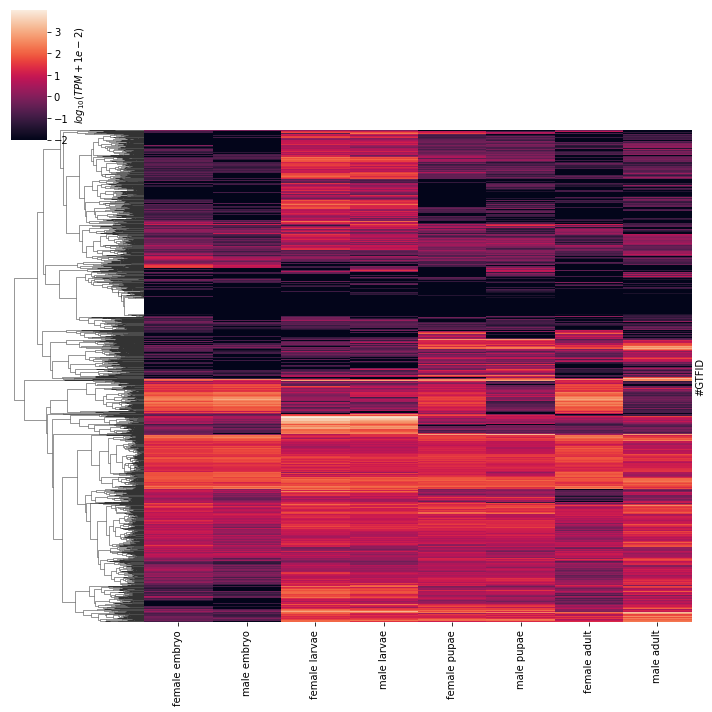

In [16]:

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Assuming dftpm is your DataFrame
dftpmi = mean_df.loc[list(hgt_genes),:]


dftpmi = dftpmi.apply(lambda x: np.log10(x + 1e-2))
# Plotting the clustermap
cluster_map = sns.clustermap(dftpmi, yticklabels=False,col_cluster=False)
plt.setp(cluster_map.ax_heatmap.yaxis.get_majorticklabels(), rotation=0)  # Suppress y axis dendrogram
cbar = cluster_map.ax_heatmap.collections[0].colorbar  # Get colorbar object
cbar.set_label(r'$log_{10}(TPM+1e-2)$')  # Label the colorbar
plt.savefig('figures/mean_stage_rnaseq_heatmap.svg',format='svg',bbox_inches='tight')
plt.show()

## Glyoxylate shunt

In [16]:
icl_gene='LOC119083098'

ms_gene='LOC119083097'

PEPCK1="Pepck1"
CPT1="whd"

In [17]:
stages=['embryo','larvae','pupae','adult']
mean_df=pd.DataFrame()
for s in stages:
    d=stage_tpm.loc[:,[x for x in stage_tpm.columns if s in x]].mean(axis=1)
    mean_df.loc[:,s]=d


In [18]:
mean_df.loc[icl_gene]


embryo     820.297333
larvae      16.814100
pupae      389.401000
adult     1486.345000
Name: LOC119083098, dtype: float64

In [19]:
mean_df.loc[ms_gene]

embryo    253.106667
larvae     26.601175
pupae     227.523750
adult     299.291750
Name: LOC119083097, dtype: float64

In [20]:
from scipy import stats

In [21]:
stats.pearsonr(stage_tpm.loc[PEPCK1],stage_tpm.loc[icl_gene])

(0.9131801371943237, 1.2326736405560105e-07)

In [22]:
stats.pearsonr(stage_tpm.loc[CPT1],stage_tpm.loc[icl_gene])

(0.8113102727347287, 4.385598081360503e-05)

In [23]:
stats.pearsonr(stage_tpm.loc[PEPCK1],stage_tpm.loc[ms_gene])

(0.5645104965243117, 0.01466125460602486)

In [24]:
stats.pearsonr(stage_tpm.loc[CPT1],stage_tpm.loc[ms_gene])

(0.48030753530167397, 0.04364807944668773)

In [25]:
dftpmi = mean_df.loc[list(hgt_genes),:]
for index, row in dftpmi.iterrows():
    dftpmi.loc[index,'description']=dfriso[dfriso.gene==index].description.values[0]

In [26]:
stages=['embryo','larvae','pupae','adult']
mean_df=pd.DataFrame()
for s in stages:
    d=stage_tpm.loc[:,[x for x in stage_tpm.columns if s in x]].mean(axis=1)
    mean_df.loc[:,s]=d

mean_df = mean_df[mean_df.max(axis=1) > 0]
mean_df.shape[0]

18151

In [27]:
max_df=mean_df.idxmax(axis=1).to_frame(name="max_column")

In [28]:
len(set(max_df.index)&hgt_genes)

1466

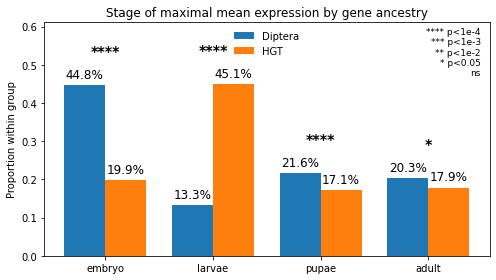

HGT larvae proportion: 0.4508867667121419
Diptera larvae proportion: 0.13306022122081115
Larvae chi-square p-value: 4.785124695134597e-208
Larvae significance: ****


In [29]:
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

# Counts
hgt = dict(Counter(max_df.loc[list(set(max_df.index) & hgt_genes), :].max_column))
dipt = dict(Counter(max_df.loc[list(set(max_df.index) & dipt_genes), :].max_column))

df = pd.DataFrame({'HGT': hgt, 'Diptera': dipt})

# Stage order
stages = ['embryo', 'larvae', 'pupae', 'adult']

# Keep stages in this order, fill missing categories with 0
df = df.reindex(stages).fillna(0)

# Proportion of each stage WITHIN each group columns sum to 1
prop = df.div(df.sum(axis=0), axis=1)

# Total counts in each group
total_hgt = df['HGT'].sum()
total_dipt = df['Diptera'].sum()

# Convert p-values to significance stars
def p_to_stars(p):
    if p < 0.0001:
        return "****"
    elif p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return "ns"

# Chi-squared p-value for each stage:
# in stage vs not in stage, comparing HGT vs Diptera
pvals = {}
dofs = {}
chi2s = {}
for stage in stages:
    hgt_in = df.loc[stage, 'HGT']
    dipt_in = df.loc[stage, 'Diptera']

    hgt_out = total_hgt - hgt_in
    dipt_out = total_dipt - dipt_in

    table = np.array([
        [hgt_in, hgt_out],
        [dipt_in, dipt_out]
    ])

    chi2, p, dof, expected = chi2_contingency(table)
    pvals[stage] = p
    dofs[stage] = dof
    chi2s[stage]= chi2 
x = np.arange(len(stages))
w = 0.38

fig, ax = plt.subplots(figsize=(7, 4))

ax.bar(x - w/2, prop['Diptera'], width=w, label='Diptera')
ax.bar(x + w/2, prop['HGT'], width=w, label='HGT')

# Label both bars with percentages and add significance stars
for i, stage in enumerate(stages):
    h = prop.loc[stage, 'HGT']
    d = prop.loc[stage, 'Diptera']
    p = pvals[stage]

    ax.text(
        i + w/2,
        h + 0.01,
        f"{h*100:.1f}%",
        ha='center',
        va='bottom',
        fontsize=12
    )

    ax.text(
        i - w/2,
        d + 0.01,
        f"{d*100:.1f}%",
        ha='center',
        va='bottom',
        fontsize=12
    )

    # Significance stars above the taller bar
    y_star = max(h, d) + 0.07

    ax.text(
        i,
        y_star,
        p_to_stars(p),
        ha='center',
        va='bottom',
        fontsize=14,
        fontweight='bold'
    )

ax.set_xticks(x)
ax.set_xticklabels(stages)
ax.set_ylabel("Proportion within group")
ax.set_ylim(0, max(prop.max()) + 0.16)
ax.set_title("Stage of maximal mean expression by gene ancestry")
ax.legend(frameon=False)

# Significance legend
ax.text(
    0.98,
    0.98,
    "**** p<1e-4\n*** p<1e-3\n** p<1e-2\n* p<0.05\nns",
    transform=ax.transAxes,
    ha='right',
    va='top',
    fontsize=9
)

plt.tight_layout()

plt.savefig('figures/maximal_expression_stage.svg', format='svg')
plt.show()

# Print larval proportions and p-value
print("HGT larvae proportion:", prop.loc['larvae', 'HGT'])
print("Diptera larvae proportion:", prop.loc['larvae', 'Diptera'])
print("Larvae chi-square p-value:", pvals['larvae'])
print("Larvae significance:", p_to_stars(pvals['larvae']))

In [30]:
formatted_pvals = {k: f"{v:.3g}" for k, v in pvals.items()}
[float(formatted_pvals[x]) for x in formatted_pvals]

[5.97e-74, 4.79e-208, 7.06e-05, 0.0334]

In [31]:
formatted_chi2s = {k: f"{v:.3g}" for k, v in chi2s.items()}
[float(formatted_chi2s[x]) for x in formatted_chi2s]

[331.0, 947.0, 15.8, 4.52]

In [32]:
dofs

{'embryo': 1, 'larvae': 1, 'pupae': 1, 'adult': 1}

In [33]:
hgt

{'embryo': 292, 'pupae': 251, 'larvae': 661, 'adult': 262}

In [34]:
dipt

{'embryo': 5466, 'adult': 2473, 'larvae': 1624, 'pupae': 2642}

In [35]:
1624/12205

0.13306022122081115

In [36]:
 5466+2642+1624+2473

12205

In [37]:
661+251+292+262

1466

In [17]:
tissues_meta=metadata[(metadata["Bioproject Accession"]=='PRJNA1109384')|(metadata['Sample Name'].str.contains("Salivary gland"))]
nmap={x:"adult"+x.split(",")[-1].replace(")","")+" "+x.split('(')[0] for x in tissues_meta['Sample Name']}
tissues_meta['name']=[nmap[x].lower().replace("adult female salivary glands","larval female salivary glands") for x in tissues_meta['Sample Name']]
tissues_tpm=tpm.loc[:,tissues_meta.index]
tissues_tpm.columns=[tissues_meta.loc[x,'name'] for x in tissues_tpm.columns]

stages=set(tissues_tpm.columns)
mean_df=pd.DataFrame()
for s in stages:
    d=tissues_tpm.loc[:,s].mean(axis=1)
    mean_df.loc[:,s]=d

/tmp/ipykernel_1063602/303101583.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  tissues_meta['name']=[nmap[x].lower().replace("adult female salivary glands","larval female salivary glands") for x in tissues_meta['Sample Name']]


In [26]:
mean_df_tissue=mean_df.loc[list(hgt_genes),:]
mean_df_all=pd.concat([mean_df_stage.loc[list(hgt_genes),:],mean_df_tissue],axis=1)
for index, row in mean_df_all.iterrows():
    mean_df_all.loc[index,'description']=dfriso[dfriso.gene==index].description.values[0]
mean_df_all.to_csv("outputs/htgs_mean_tissue_stage_concat_tpms.tsv",sep="\t")

/n/home11/rkapoor/.conda/envs/rishabh/lib/python3.9/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
/n/home11/rkapoor/.conda/envs/rishabh/lib/python3.9/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


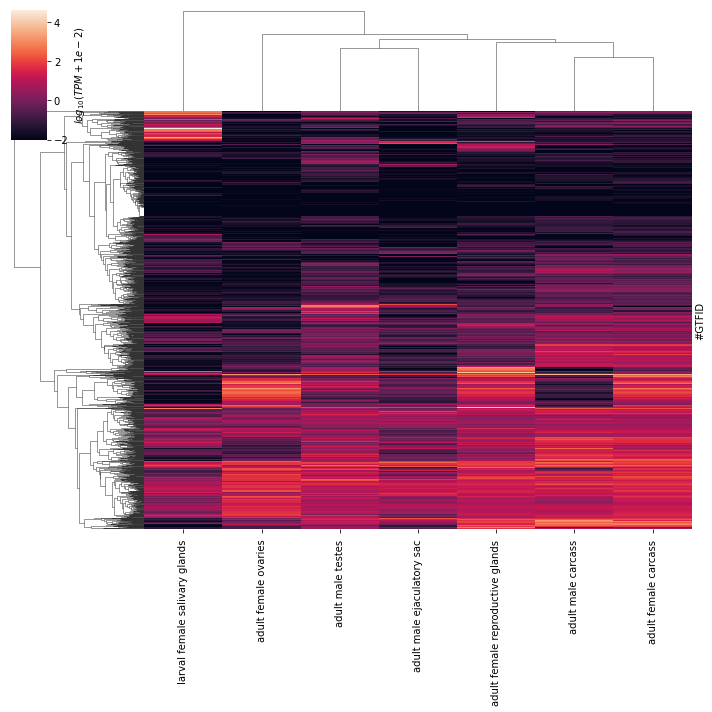

In [39]:

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Assuming dftpm is your DataFrame
dftpmi = mean_df.loc[list(hgt_genes),:]


dftpmi = dftpmi.apply(lambda x: np.log10(x + 1e-2))
# Plotting the clustermap
cluster_map = sns.clustermap(dftpmi, yticklabels=False)
plt.setp(cluster_map.ax_heatmap.yaxis.get_majorticklabels(), rotation=0)  # Suppress y axis dendrogram
cbar = cluster_map.ax_heatmap.collections[0].colorbar  # Get colorbar object
cbar.set_label(r'$log_{10}(TPM+1e-2)$')  # Label the colorbar
plt.savefig('figures/mean_tissues_rnaseq_heatmap.svg',format='svg',bbox_inches='tight')
plt.show()

In [41]:
mean_df = mean_df[mean_df.max(axis=1) > 0]
max_df=mean_df.idxmax(axis=1).to_frame(name="max_column")

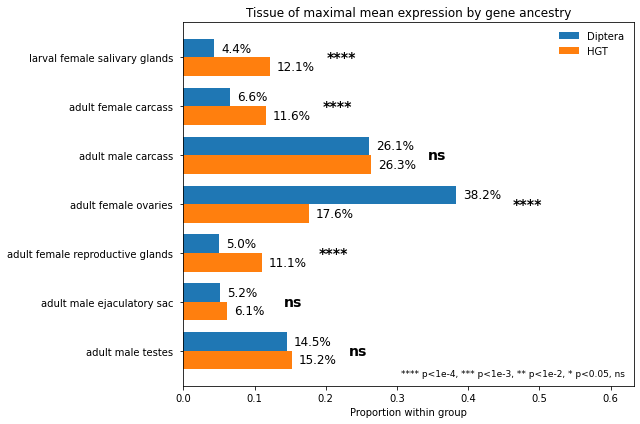

In [34]:
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

# Counts
hgt = dict(Counter(max_df.loc[list(set(max_df.index) & hgt_genes), :].max_column))
dipt = dict(Counter(max_df.loc[list(set(max_df.index) & dipt_genes), :].max_column))

df = pd.DataFrame({'HGT': hgt, 'Diptera': dipt})

# Stage / tissue order
stages = [
    'larval female salivary glands ',
    'adult female carcass ',
    'adult male carcass ',
    'adult female ovaries ',
    'adult female reproductive glands ',
    'adult male ejaculatory sac ',
    'adult male testes '
]

# Keep stages in this order, filling missing categories with 0
df = df.reindex(stages).fillna(0)

# Proportion of each stage WITHIN each group
# columns sum to 1
prop = df.div(df.sum(axis=0), axis=1)

# Total counts in each group
total_hgt = df['HGT'].sum()
total_dipt = df['Diptera'].sum()

# Convert p-values to significance stars
def p_to_stars(p):
    if p < 0.0001:
        return "****"
    elif p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return "ns"

# Chi-squared p-value for each stage:
# in category vs not in category, comparing HGT vs Diptera
pvals = {}
dofs = {}
chi2s ={}
for stage in stages:
    hgt_in = df.loc[stage, 'HGT']
    dipt_in = df.loc[stage, 'Diptera']

    hgt_out = total_hgt - hgt_in
    dipt_out = total_dipt - dipt_in

    table = np.array([
        [hgt_in, hgt_out],
        [dipt_in, dipt_out]
    ])

    chi2, p, dof, expected = chi2_contingency(table)
    pvals[stage] = p
    dofs[stage] = dof
    chi2s[stage]= chi2 

# Plot
y = np.arange(len(stages))
w = 0.38

fig, ax = plt.subplots(figsize=(9, 6))

ax.barh(y - w/2, prop['Diptera'], height=w, label='Diptera')
ax.barh(y + w/2, prop['HGT'], height=w, label='HGT')

# Label bars with percentages and annotate chi-squared significance
for i, stage in enumerate(stages):
    h = prop.loc[stage, 'HGT']
    d = prop.loc[stage, 'Diptera']
    p = pvals[stage]

    # Diptera percentage label
    ax.text(
        d + 0.01,
        i - w/2,
        f"{d*100:.1f}%",
        ha='left',
        va='center',
        fontsize=12
    )

    # HGT percentage label
    ax.text(
        h + 0.01,
        i + w/2,
        f"{h*100:.1f}%",
        ha='left',
        va='center',
        fontsize=12
    )

    # Significance stars to the right of the longer bar
    x_star = max(h, d) + 0.08t

    ax.text(
        x_star,
        i,
        p_to_stars(p),
        ha='left',
        va='center',
        fontsize=14,
        fontweight='bold'
    )

ax.set_yticks(y)
ax.set_yticklabels(stages)
ax.set_xlabel("Proportion within group")
ax.set_title("Tissue of maximal mean expression by gene ancestry")
ax.legend(frameon=False)

# Make room for percentage labels and stars
ax.set_xlim(0, max(prop.max()) + 0.25)

# Optional: put first tissue at the top
ax.invert_yaxis()

# Significance legend
ax.text(
    0.98,
    0.02,
    "**** p<1e-4, *** p<1e-3, ** p<1e-2, * p<0.05, ns",
    transform=ax.transAxes,
    ha='right',
    va='bottom',
    fontsize=9
)

plt.tight_layout()

plt.savefig('figures/maximal_expression_tissue.svg', format='svg')
plt.show()

In [35]:
formatted_pvals = {k: f"{v:.3g}" for k, v in pvals.items()}
[float(formatted_pvals[x]) for x in formatted_pvals]

[6.88e-37, 3.37e-12, 0.872, 5.42e-55, 1.26e-21, 0.185, 0.479]

In [36]:
formatted_chi2s = {k: f"{v:.3g}" for k, v in chi2s.items()}
[float(formatted_chi2s[x]) for x in formatted_chi2s]

[161.0, 48.5, 0.0261, 244.0, 91.3, 1.76, 0.501]

In [38]:
hgt

{'adult female carcass ': 172,
 'adult male carcass ': 391,
 'larval female salivary glands ': 180,
 'adult male ejaculatory sac ': 90,
 'adult female reproductive glands ': 164,
 'adult female ovaries ': 261,
 'adult male testes ': 226}

In [ ]:
180/

In [40]:
np.sum([hgt[x] for x in hgt])

1484

In [39]:
dipt

{'adult male carcass ': 3203,
 'adult female ovaries ': 4689,
 'adult male testes ': 1779,
 'adult female carcass ': 812,
 'larval female salivary glands ': 534,
 'adult female reproductive glands ': 609,
 'adult male ejaculatory sac ': 639}

In [41]:
np.sum([dipt[x] for x in hgt])

12265

## DeSeq2 Larval vs. Not

In [25]:
import pandas as pd
import os
dfco=pd.read_csv("datasets/RNA_seq/GCF_014529535.2-RS_2026_02_gene_expression_counts.txt",sep="\t",index_col=0)


In [70]:
stages_meta=metadata[metadata["Bioproject Accession"]=='PRJNA291918']
nmap={'Salivary glands (Bradysia coprophila, 4th instar larval eyespot stage 10x5, female)': 'Salivary glands',
 'Salivary glands (Bradysia coprophila, 4th instar larval eyespot stage 12x6, female)': 'Salivary glands',
 'Salivary glands (Bradysia coprophila, 4th instar larval eyespot stage 14x7, female)':'Salivary glands',
 'Salivary glands (Bradysia coprophila, 4th instar larval eyespot stage 8x4, female)': 'Salivary glands',
 'Salivary glands (Bradysia coprophila, mixture of 4th instar larval eyespot stages Edge Eye and Drop Jaw (EEDJ), female)': 'Salivary glands',
 'Whole adult (Bradysia coprophila, mixed, female)': 'female adult',
 'Whole adult (Bradysia coprophila, mixed, male)': 'male adult',
 'Whole embryo (Bradysia coprophila, 2 hours - 2 days, female)':'female embryo',
 'Whole embryo (Bradysia coprophila, 2 hours - 2 days, male)':'male embryo',
 'Whole larvae (Bradysia coprophila, mixed, female)':'female larvae',
 'Whole larvae (Bradysia coprophila, mixed, male)':'male larvae',
 'Whole pupae (Bradysia coprophila, mixed, female)':'female pupae',
 'Whole pupae (Bradysia coprophila, mixed, male)':'male pupae'}
stages_meta['name']=[nmap[x] for x in stages_meta['Sample Name']]
stages_meta=stages_meta[stages_meta.name!='Salivary glands']

# Keep sample IDs as unique count-matrix column names
dfc = dfco.loc[:, stages_meta.index].copy()
dfc.index.name = ''
dfc.columns.name = ''

# Metadata rows must match count columns exactly
meta = pd.DataFrame(index=dfc.columns)
meta.index.name = ''

# Repeated condition labels are fine; repeated sample IDs are not
meta["c"] = [
    "larvae" in stages_meta.loc[sample_id, "name"]
    for sample_id in dfc.columns
]


dfc.to_csv("outputs/developmental_counts.csv")
meta.to_csv("outputs/larvae_non_larvae_meta.csv")

dfc

/tmp/ipykernel_2997000/3034617900.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  stages_meta['name']=[nmap[x] for x in stages_meta['Sample Name']]


,SRR9969366,SRR9969367,SRR9969368,SRR9969369,SRR9969370,SRR9969371,SRR9969372,SRR9969373,SRR9969374,SRR9969375,SRR9969376,SRR9969377,SRR9969378,SRR9969379,SRR9969380,SRR9969381,SRR9969382,SRR9969383
,,,,,,,,,,,,,,,,,,
LOC119065975,6,2,1,12,711,746,0,4,316,267,182,126,40,46,34,47,8,12
LOC119065976,418,348,312,468,164,185,248,322,337,235,1202,1077,468,509,1008,712,259,868
Rabex-5,455,639,589,577,223,303,546,847,306,298,1123,1015,293,343,1350,1459,836,2335
LOC119065997,143,142,163,199,108,98,103,150,114,105,575,568,201,177,974,777,163,401
Pldn,138,177,120,130,61,46,139,200,84,38,155,176,77,58,179,166,133,453
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
LOC119070228,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
LOC145389384,2,8,0,2,0,8,4,6,10,2,4,4,2,4,6,4,0,2
LOC145389385,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [71]:
meta

,c
,
SRR9969366,False
SRR9969367,False
SRR9969368,False
SRR9969369,False
SRR9969370,True
SRR9969371,True
SRR9969372,False
SRR9969373,False
SRR9969374,True


In [39]:
%%bash
my_packages=${HOME}/R/ifxrstudio/RELEASE_3_16
rstudio_singularity_image="/n/singularity_images/informatics/ifxrstudio/ifxrstudio:RELEASE_3_16.sif"
singularity exec --cleanenv --env R_LIBS_USER=${my_packages} ${rstudio_singularity_image} Rscript scripts/deseq2Counts_copro.R outputs/developmental_counts.csv outputs/larvae_non_larvae_meta.csv True False larval


Warning message:
In DESeqDataSet(se, design = design, ignoreRank) :
  some variables in design formula are characters, converting to factors
estimating size factors
estimating dispersions
gene-wise dispersion estimates
mean-dispersion relationship
final dispersion estimates
fitting model and testing
-- replacing outliers and refitting for 503 genes
-- DESeq argument 'minReplicatesForReplace' = 7 
-- original counts are preserved in counts(dds)
estimating dispersions
fitting model and testing


In [9]:

d=pd.read_csv("outputs/deseq2larval.csv",index_col=0)
dipt=d.loc[list(dipt_genes),:]
hdf=d.loc[list(hgt_genes),:]
print(dipt[(dipt.padj<.05)&(dipt.log2FoldChange>0)].shape[0],dipt.shape[0],dipt[(dipt.padj<.05)&(dipt.log2FoldChange>0)].shape[0]/dipt.shape[0])
print(hdf[(hdf.padj<.05)&(hdf.log2FoldChange>0)].shape[0],hdf.shape[0],hdf[(hdf.padj<.05)&(hdf.log2FoldChange>0)].shape[0]/hdf.shape[0])


1753 12381 0.14158791696955011
600 1517 0.39551746868820037


In [10]:
from scipy.stats import chi2_contingency

table = [
    [dipt[(dipt.padj<.05)&(dipt.log2FoldChange>0)].shape[0],dipt.shape[0]-dipt[(dipt.padj<.05)&(dipt.log2FoldChange>0)].shape[0]],
    [hdf[(hdf.padj<.05)&(hdf.log2FoldChange>0)].shape[0],hdf.shape[0]-hdf[(hdf.padj<.05)&(hdf.log2FoldChange>0)].shape[0]]
]

chi2, p, dof, expected = chi2_contingency(table)
print("chi2:", chi2)
print("p:", p)
print("expected:\n", expected)

/n/home11/rkapoor/.conda/envs/rishabh/lib/python3.9/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.23.5
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


chi2: 617.7855676320628
p: 2.2666763212390677e-136
expected:
 [[ 2096.16441215 10284.83558785]
 [  256.83558785  1260.16441215]]


In [11]:
h=hdf[(hdf.padj<.05)&(hdf.log2FoldChange>0)]
for index, row in h.iterrows():
    h.loc[index,'description']=dfriso[dfriso.gene==index].description.values[0]
h.to_csv('outputs/larval_upregulated_hgts.tsv',sep='\t')

/tmp/ipykernel_4023274/2706653727.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  h.loc[index,'description']=dfriso[dfriso.gene==index].description.values[0]


In [1]:
import pandas as pd

In [66]:
h=pd.read_csv('outputs/larval_upregulated_hgts.csv',index_col=0)
h['protein']=[x.split(" ")[0] for x in h.description]
h['description']=[" ".join(x.split(" ")[1:]).replace(" [Bradysia coprophila]", "") for x in h.description]
h.to_csv('outputs/larval_upregulated_hgts.csv')

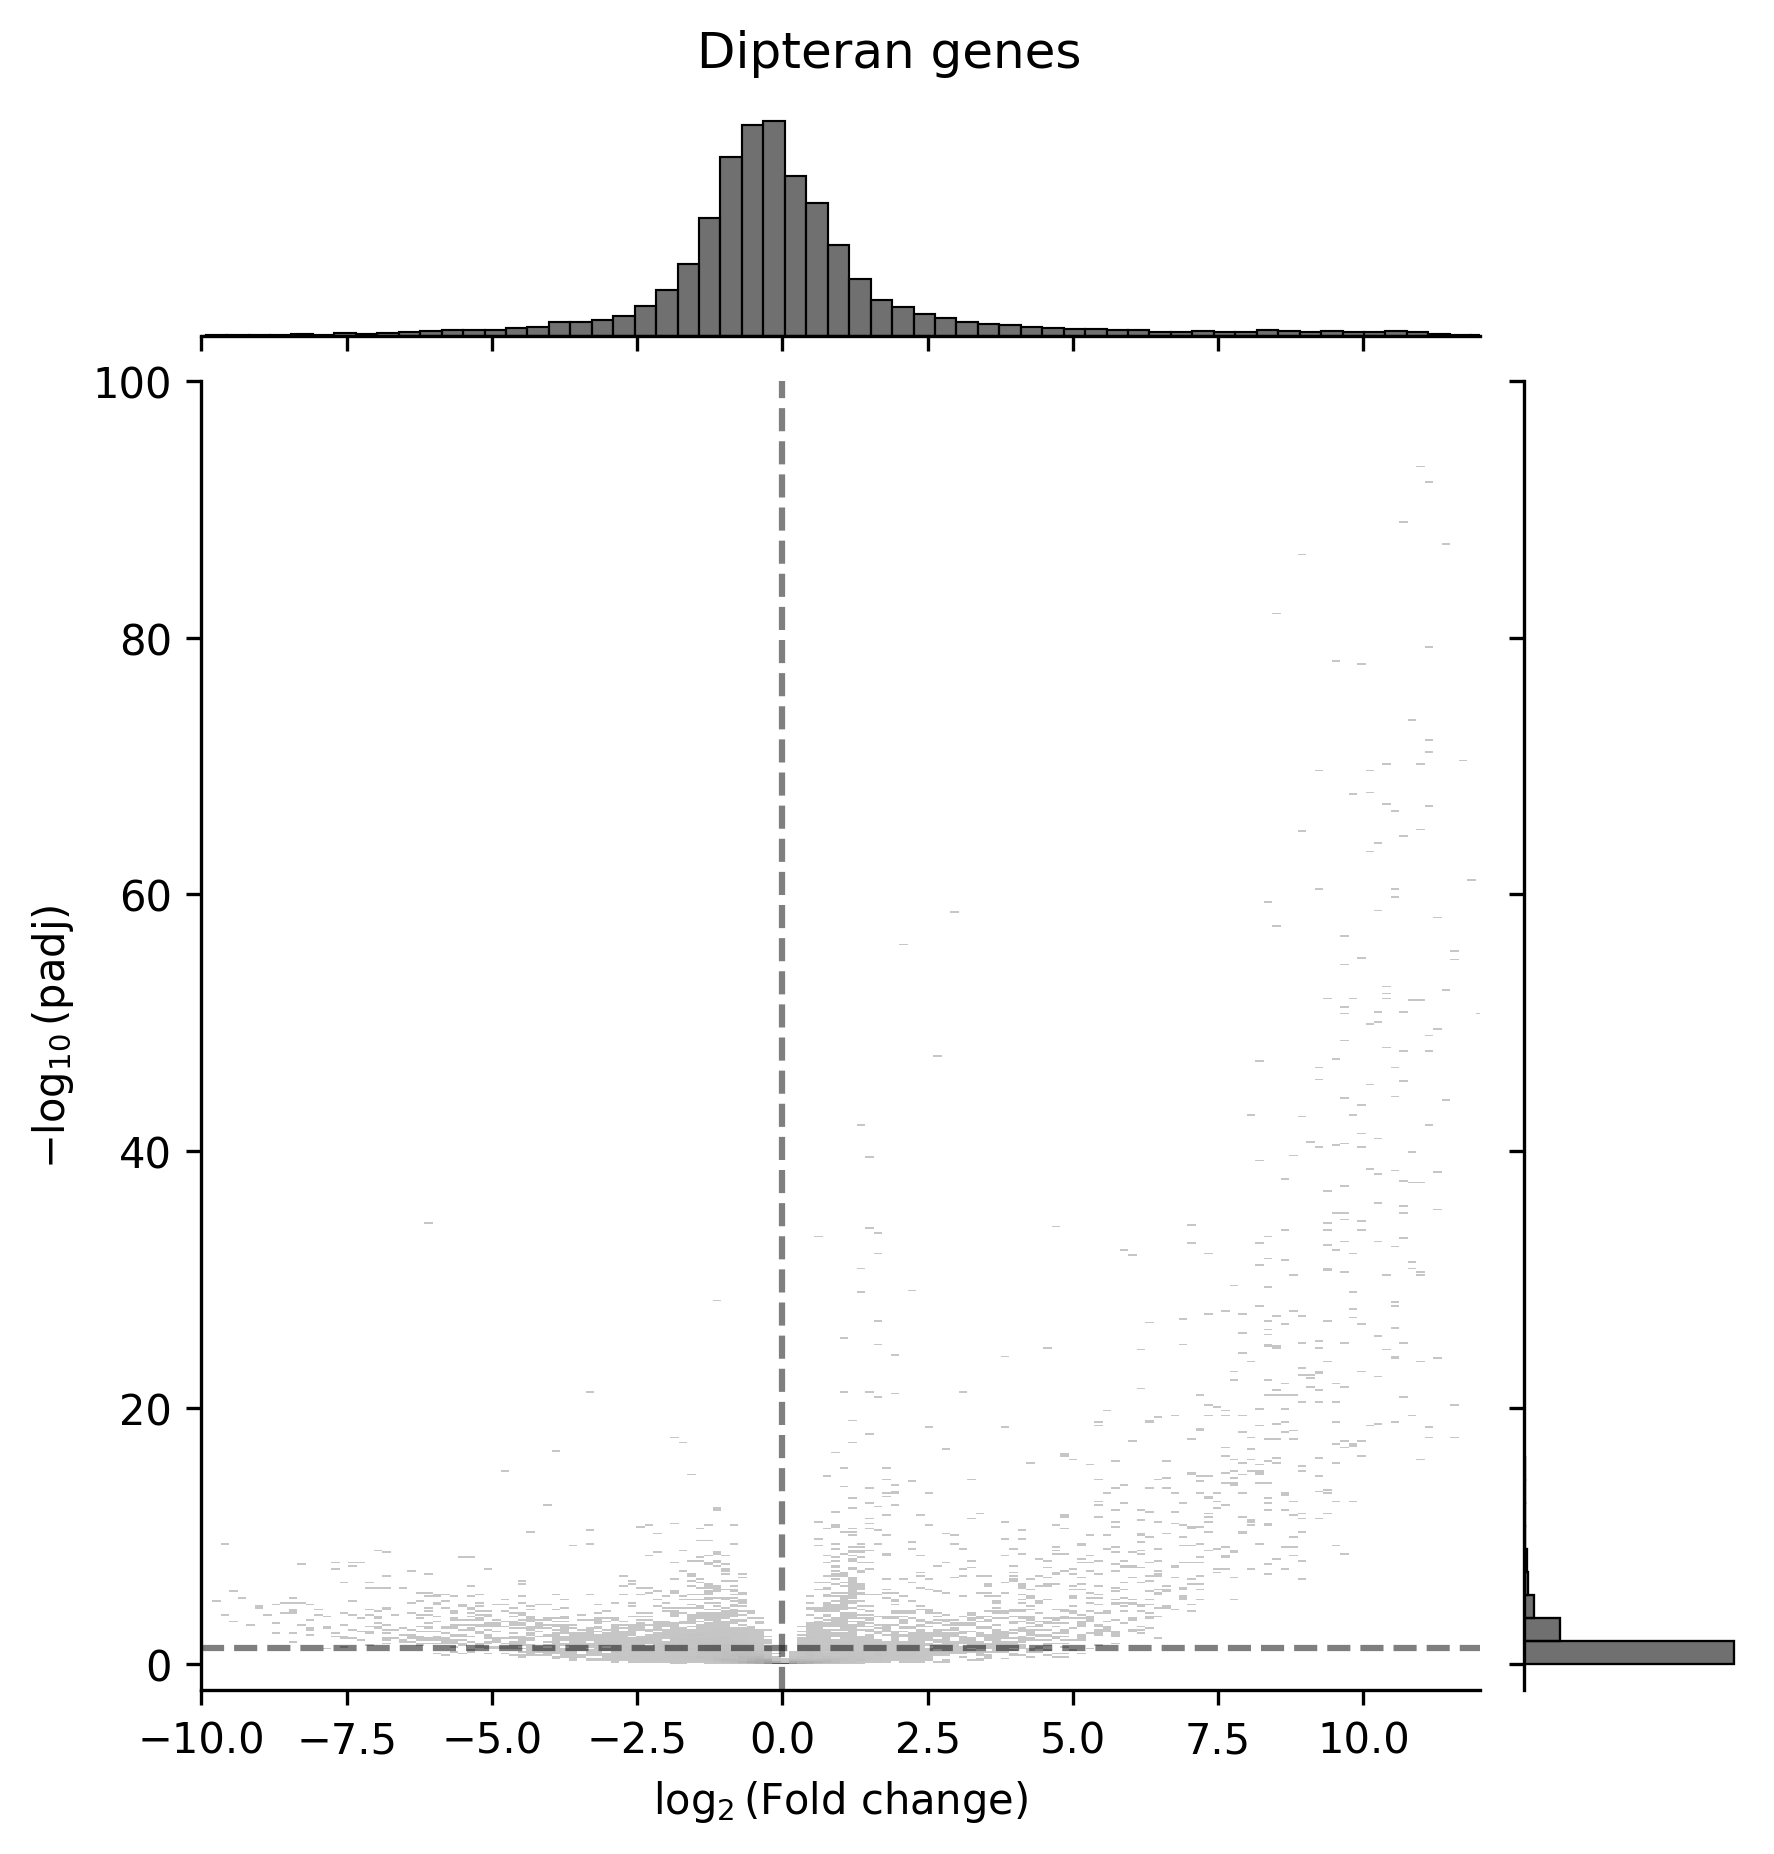

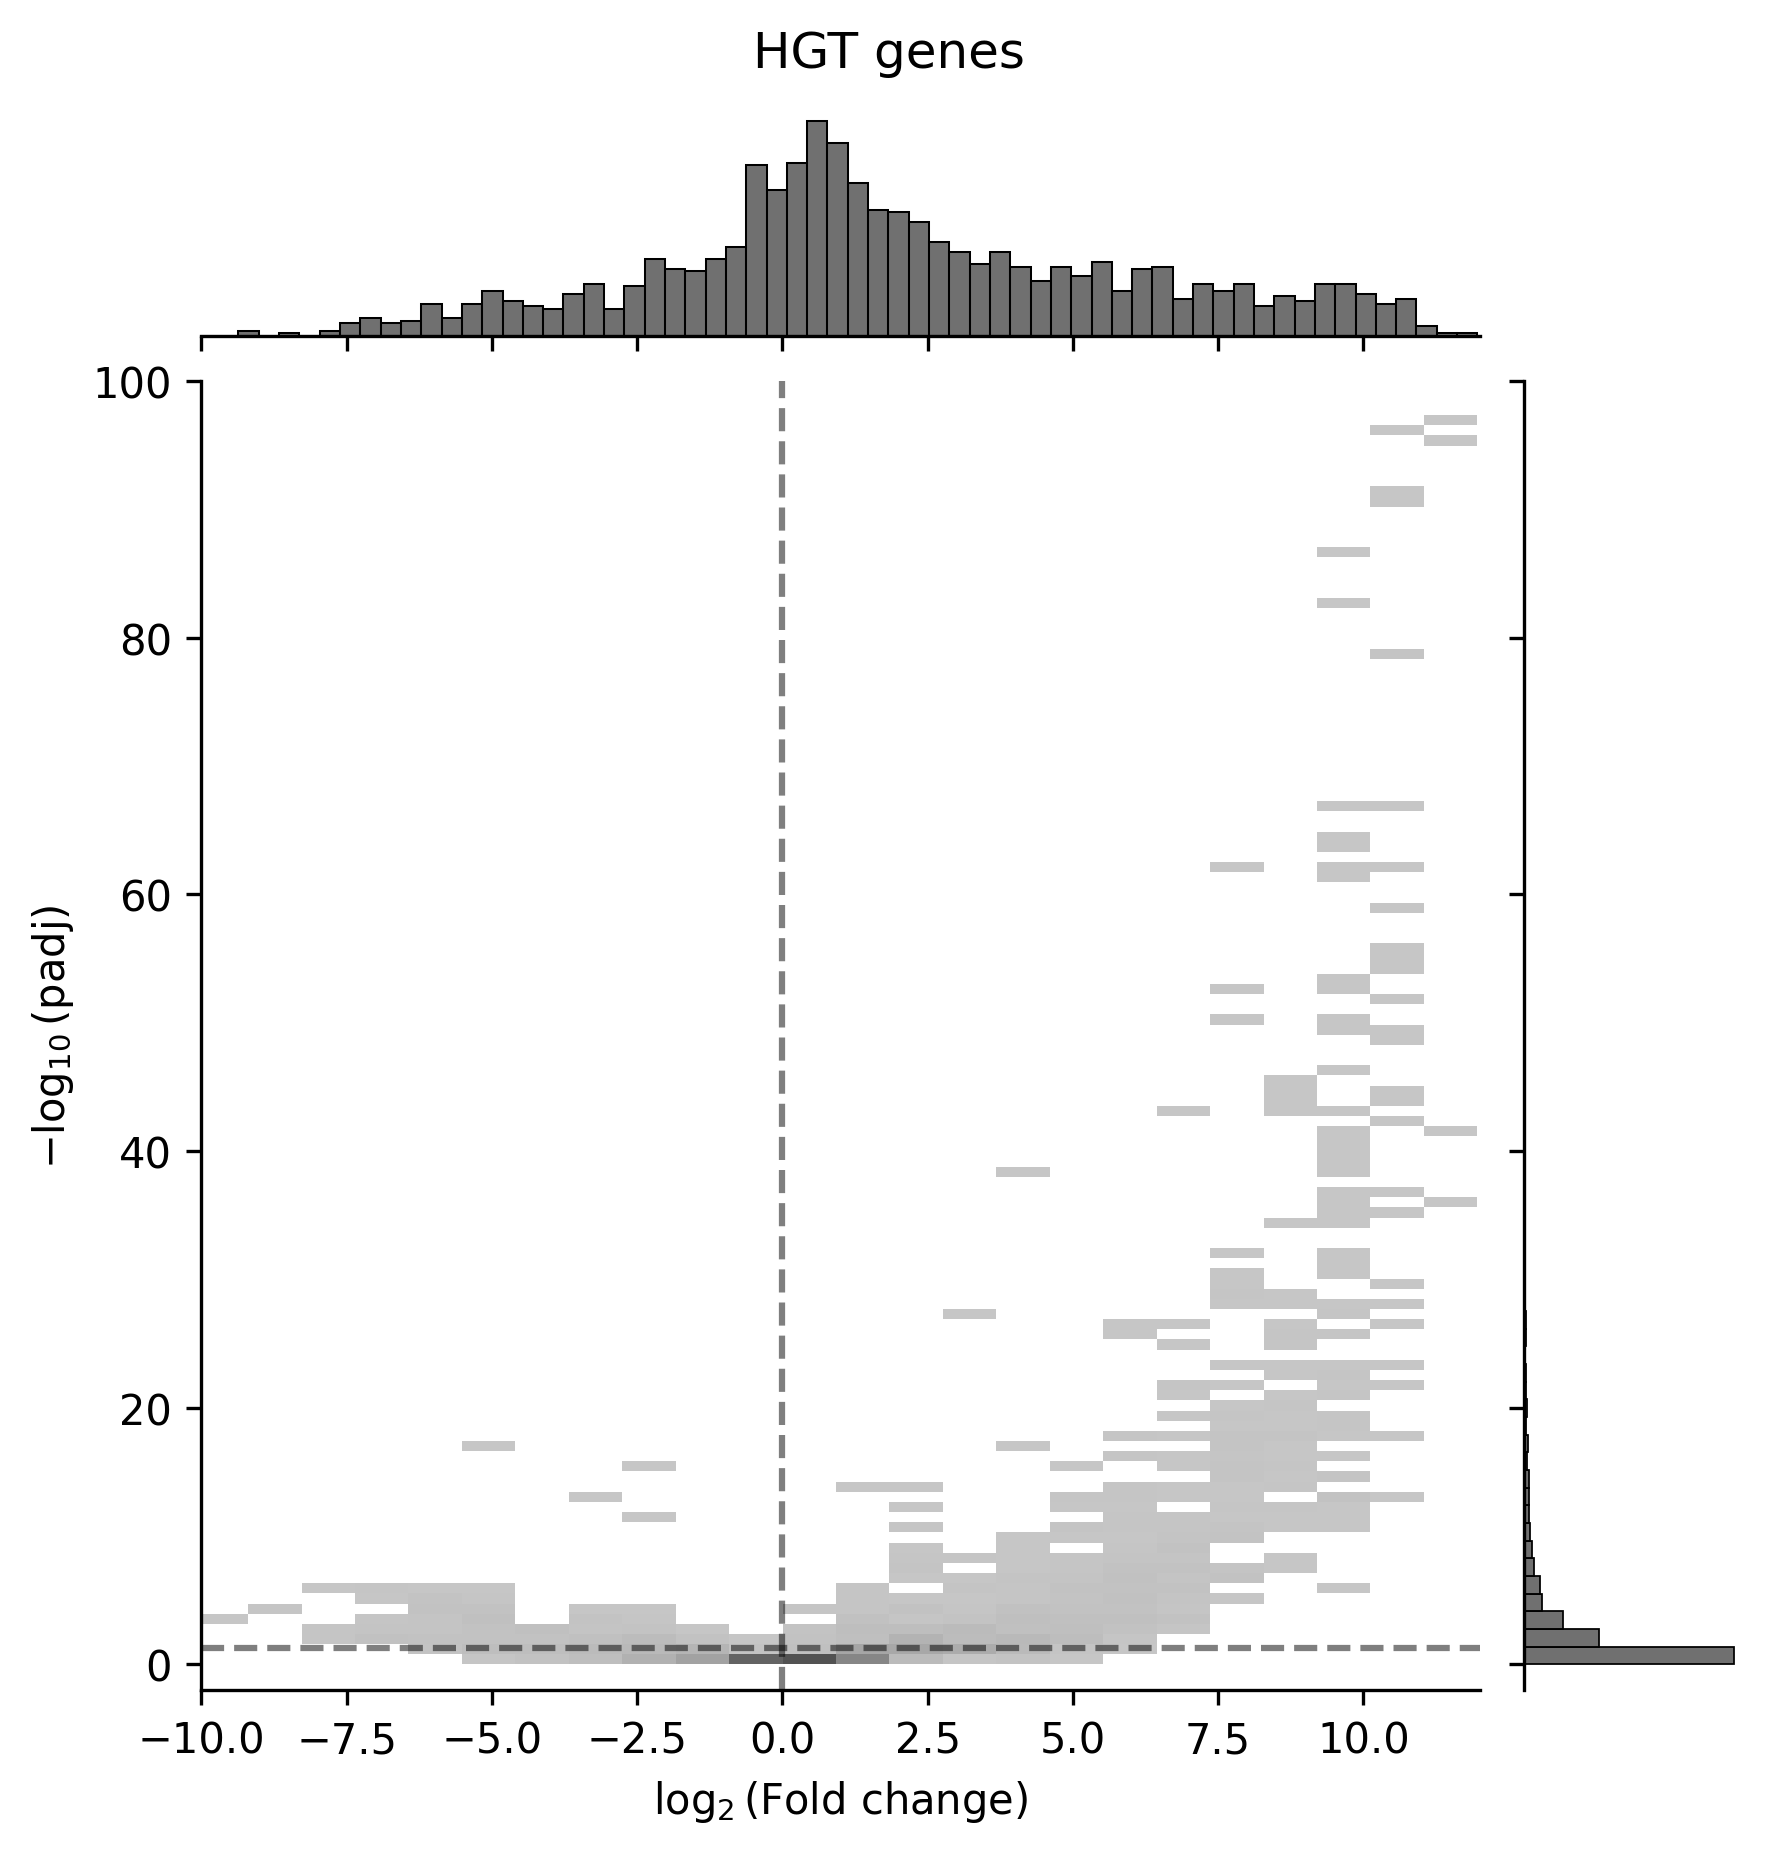

In [67]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Compute -log10 adjusted p-values
dipt['-log10(padj)'] = -np.log10(dipt.padj)
hdf['-log10(padj)'] = -np.log10(hdf.padj)

# Significance threshold
sig_thresh = -np.log10(0.05)

# Jointplot for Dipteran genes
g1 = sns.jointplot(
    data=dipt,
    x='log2FoldChange',
    y='-log10(padj)',
    kind='hist',
    color='0.25',
    marginal_kws=dict(bins=100, fill=True),
    xlim=(-10, 12),
    ylim=(-2, 100)
)

g1.ax_joint.axhline(sig_thresh, color='black', linestyle='dashed', alpha=0.5)
g1.ax_joint.axvline(0, color='black', linestyle='dashed', alpha=0.5)
g1.ax_joint.set_ylabel(r"$-\log_{10}(\mathrm{padj})$")
g1.ax_joint.set_xlabel(r"$\log_{2}$"+"(Fold change)")
g1.fig.suptitle("Dipteran genes", y=1.02)

g1.savefig(
    'figures/dipteran_larval_volcano.svg',
    format='svg',
    bbox_inches='tight'
)

g1.savefig(
    'figures/dipteran_larval_volcano.png',
    format='png',
    bbox_inches='tight'
)

# Jointplot for HGT genes
g2 = sns.jointplot(
    data=hdf,
    x='log2FoldChange',
    y='-log10(padj)',
    kind='hist',
    color='0.25',
    marginal_kws=dict(bins=100, fill=True),
    xlim=(-10, 12),
    ylim=(-2, 100)
)

g2.ax_joint.axhline(sig_thresh, color='black', linestyle='dashed', alpha=0.5)
g2.ax_joint.axvline(0, color='black', linestyle='dashed', alpha=0.5)
g2.ax_joint.set_ylabel(r"$-\log_{10}(\mathrm{padj})$")
g2.ax_joint.set_xlabel(r"$\log_{2}$"+"(Fold change)")
g2.fig.suptitle("HGT genes", y=1.02)

g2.savefig(
    'figures/hgt_larval_volcano.png',
    format='png',
    bbox_inches='tight'
)

g2.savefig(
    'figures/hgt_larval_volcano.svg',
    format='svg',
    bbox_inches='tight'
)


plt.show()


## DeSeq2 Radiated vs. Not

In [75]:
stages_meta=metadata[metadata["Bioproject Accession"]=='PRJNA928089']


dfc=dfco.loc[:,stages_meta.index]
dfc.index.name=''

In [76]:
dfc.columns.name=''

In [77]:
nmap={'SRR23237569':False, 'SRR23237570':False, 'SRR23237571':False, 'SRR23237572':True, 'SRR23237573':True, 'SRR23237574':True}

In [78]:
df=pd.DataFrame.from_dict(nmap, orient='index')
df.columns=['c']

In [79]:
dfc.to_csv('outputs/irradiation_counts.csv')

In [50]:
df.to_csv("outputs/irradiation_meta.csv")

In [51]:
%%bash
my_packages=${HOME}/R/ifxrstudio/RELEASE_3_16
rstudio_singularity_image="/n/singularity_images/informatics/ifxrstudio/ifxrstudio:RELEASE_3_16.sif"
singularity exec --cleanenv --env R_LIBS_USER=${my_packages} ${rstudio_singularity_image} Rscript scripts/deseq2Counts_copro.R outputs/irradiation_counts.csv outputs/irradiation_meta.csv True False 'irradiated'


Warning message:
In DESeqDataSet(se, design = design, ignoreRank) :
  some variables in design formula are characters, converting to factors
estimating size factors
estimating dispersions
gene-wise dispersion estimates
mean-dispersion relationship
final dispersion estimates
fitting model and testing


In [27]:
import pandas as pd
d=pd.read_csv("outputs/deseq2irradiated.csv",index_col=0)
dipt=d.loc[list(dipt_genes),:]
hdf=d.loc[list(hgt_genes),:]
print(dipt[(dipt.padj<.05)&(dipt.log2FoldChange>0)].shape[0],dipt.shape[0],dipt[(dipt.padj<.05)&(dipt.log2FoldChange>0)].shape[0]/dipt.shape[0])
print(hdf[(hdf.padj<.05)&(hdf.log2FoldChange>0)].shape[0],hdf.shape[0],hdf[(hdf.padj<.05)&(hdf.log2FoldChange>0)].shape[0]/hdf.shape[0])

264 12381 0.021322994911558032
40 1517 0.026367831245880026


In [28]:
d[(d.padj<.05)&(d.log2FoldChange>0)].shape[0]

338

In [81]:
from scipy.stats import chi2_contingency

table = [
    [dipt[(dipt.padj<.05)&(dipt.log2FoldChange>0)].shape[0],dipt.shape[0]-dipt[(dipt.padj<.05)&(dipt.log2FoldChange>0)].shape[0]],
    [hdf[(hdf.padj<.05)&(hdf.log2FoldChange>0)].shape[0],hdf.shape[0]-hdf[(hdf.padj<.05)&(hdf.log2FoldChange>0)].shape[0]]
]

chi2, p, dof, expected = chi2_contingency(table)
print("chi2:", chi2)
print("p:", p)
print("expected:\n", expected)

chi2: 1.3804124371278017
p: 0.2400309067907205
expected:
 [[  270.81767161 12110.18232839]
 [   33.18232839  1483.81767161]]


In [29]:
## the most strongly upregulated gene on irradiation is an HGT PARP
d.sort_values('log2FoldChange',ascending=False).index[0]

'LOC119085384'

In [83]:
h=hdf[(hdf.padj<.05)&(hdf.log2FoldChange>0)]
for index, row in h.iterrows():
    h.loc[index,'description']=dfriso[dfriso.gene==index].description.values[0]
h.to_csv('outputs/irradiation_upregulated_hgts.tsv',sep='\t')

/tmp/ipykernel_2997000/3500556187.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  h.loc[index,'description']=dfriso[dfriso.gene==index].description.values[0]


## DeSeq2 salivary vs larval whole

In [56]:
stages_meta=metadata[metadata["Bioproject Accession"]=='PRJNA291918']
nmap={'Salivary glands (Bradysia coprophila, 4th instar larval eyespot stage 10x5, female)': 'Salivary glands',
 'Salivary glands (Bradysia coprophila, 4th instar larval eyespot stage 12x6, female)': 'Salivary glands',
 'Salivary glands (Bradysia coprophila, 4th instar larval eyespot stage 14x7, female)':'Salivary glands',
 'Salivary glands (Bradysia coprophila, 4th instar larval eyespot stage 8x4, female)': 'Salivary glands',
 'Salivary glands (Bradysia coprophila, mixture of 4th instar larval eyespot stages Edge Eye and Drop Jaw (EEDJ), female)': 'Salivary glands',
 'Whole adult (Bradysia coprophila, mixed, female)': 'female adult',
 'Whole adult (Bradysia coprophila, mixed, male)': 'male adult',
 'Whole embryo (Bradysia coprophila, 2 hours - 2 days, female)':'female embryo',
 'Whole embryo (Bradysia coprophila, 2 hours - 2 days, male)':'male embryo',
 'Whole larvae (Bradysia coprophila, mixed, female)':'female larvae',
 'Whole larvae (Bradysia coprophila, mixed, male)':'male larvae',
 'Whole pupae (Bradysia coprophila, mixed, female)':'female pupae',
 'Whole pupae (Bradysia coprophila, mixed, male)':'male pupae'}
stages_meta['name']=[nmap[x] for x in stages_meta['Sample Name']]
stages_meta=stages_meta[stages_meta.name.str.contains('Salivary|female larvae')]

# Keep sample IDs as unique count-matrix column names
dfc = dfco.loc[:, stages_meta.index].copy()
dfc.index.name = ''
dfc.columns.name = ''

# Metadata rows must match count columns exactly
meta = pd.DataFrame(index=dfc.columns)
meta.index.name = ''

meta["c"] = [
     "Salivary" in stages_meta.loc[sample_id, "name"] for sample_id in dfc.columns
]

dfc.to_csv("outputs/salivary_counts.csv")
meta.to_csv("outputs/salivary_meta.csv")

/tmp/ipykernel_2919040/143610018.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  stages_meta['name']=[nmap[x] for x in stages_meta['Sample Name']]


In [57]:
%%bash
my_packages=${HOME}/R/ifxrstudio/RELEASE_3_16
rstudio_singularity_image="/n/singularity_images/informatics/ifxrstudio/ifxrstudio:RELEASE_3_16.sif"
singularity exec --cleanenv --env R_LIBS_USER=${my_packages} ${rstudio_singularity_image} Rscript scripts/deseq2Counts_copro.R outputs/salivary_counts.csv outputs/salivary_meta.csv True False salivary


Warning message:
In DESeqDataSet(se, design = design, ignoreRank) :
  some variables in design formula are characters, converting to factors
estimating size factors
estimating dispersions
gene-wise dispersion estimates
mean-dispersion relationship
final dispersion estimates
fitting model and testing
-- replacing outliers and refitting for 1745 genes
-- DESeq argument 'minReplicatesForReplace' = 7 
-- original counts are preserved in counts(dds)
estimating dispersions
fitting model and testing


In [58]:

d=pd.read_csv("outputs/deseq2salivary.csv",index_col=0)
dipt=d.loc[list(dipt_genes),:]
hdf=d.loc[list(hgt_genes),:]
print(dipt[(dipt.padj<.05)&(dipt.log2FoldChange>0)].shape[0],dipt.shape[0],dipt[(dipt.padj<.05)&(dipt.log2FoldChange>0)].shape[0]/dipt.shape[0])
print(hdf[(hdf.padj<.05)&(hdf.log2FoldChange>0)].shape[0],hdf.shape[0],hdf[(hdf.padj<.05)&(hdf.log2FoldChange>0)].shape[0]/hdf.shape[0])

972 12381 0.07850739035619093
123 1517 0.08108108108108109


In [59]:
from scipy.stats import chi2_contingency

table = [
    [dipt[(dipt.padj<.05)&(dipt.log2FoldChange>0)].shape[0],dipt.shape[0]-dipt[(dipt.padj<.05)&(dipt.log2FoldChange>0)].shape[0]],
    [hdf[(hdf.padj<.05)&(hdf.log2FoldChange>0)].shape[0],hdf.shape[0]-hdf[(hdf.padj<.05)&(hdf.log2FoldChange>0)].shape[0]]
]

chi2, p, dof, expected = chi2_contingency(table)
print("chi2:", chi2)
print("p:", p)
print("expected:\n", expected)

chi2: 0.090422391912756
p: 0.7636408570458415
expected:
 [[  975.47812635 11405.52187365]
 [  119.52187365  1397.47812635]]


In [60]:
h=hdf[(hdf.padj<.05)&(hdf.log2FoldChange>0)]
for index, row in h.iterrows():
    h.loc[index,'description']=dfriso[dfriso.gene==index].description.values[0]
h['protein']=[x.split(" ")[0] for x in h.description]
h['description']=[" ".join(x.split(" ")[1:]).replace(" [Bradysia coprophila]", "") for x in h.description]
h.to_csv('outputs/salivary_upregulated_hgts.csv')

/tmp/ipykernel_2919040/437137317.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  h.loc[index,'description']=dfriso[dfriso.gene==index].description.values[0]
/tmp/ipykernel_2919040/437137317.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  h['protein']=[x.split(" ")[0] for x in h.description]
/tmp/ipykernel_2919040/437137317.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the d